# Анализ данных (EDA)

## 1. Общие представления о дата-сете
*   **Источник данных:** датасет Unified Credit & Carbon Dataset (from Kaggle).
*   **Формат:** CSV-файл, 5000 строк, 33 столбца, объём 1,2 Мб
*   **Бизнес-контекст:** Данные моделируют домохозяйства в сельской Индии. Объединяют финансовые показатели (оценка кредитоспособности, транзакции) и агро-экологические факторы (характеристики почвы, спутниковые данные).
*   **Цель анализа:** Оценить качество данных, выявить аномалии, пропуски и взаимосвязи перед построением ML-моделей.

In [27]:
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import os
import gdown

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Загрузка данных
FILE_ID = '10zWddY15usCdpocAaw-xI-Ixy0sHwi8w'
DATA_PATH = 'synthetic_dataset.csv'

def load_dataset(file_id, output_filename):
    if not os.path.exists(output_filename):
        print("Файл не найден локально. Скачиваем с Google Диска...")
        url = f'https://drive.google.com/uc?id={file_id}'
        try:
            gdown.download(url, output_filename, quiet=False) # ВОТ ЭТА СТРОКА БЫЛА ПРОПУЩЕНА
            print("Загрузка завершена!")
        except gdown.exceptions.DownloadError as e:
            raise RuntimeError(f"Ошибка скачивания gdown: {e}") from e
    else:
        print(f"Файл '{output_filename}' найден локально. Пропускаем скачивание.")
    
    try:
        df = pd.read_csv(output_filename)
    except (pd.errors.ParserError, pd.errors.EmptyDataError) as e:
        raise RuntimeError(f"Ошибка чтения CSV: {e}") from e
    
    # Явная проверка вместо assert (как просил бот)
    if df is None:
        raise ValueError("Датасет не загружен (df is None)")
        
    return df

df = load_dataset(FILE_ID, DATA_PATH)
print(f"Данные загружены. Размер: {df.shape[0]} строк, {df.shape[1]} столбцов.")

Файл 'synthetic_dataset.csv' найден локально. Пропускаем скачивание.
Данные загружены. Размер: 5000 строк, 33 столбцов.


In [29]:
# Просмотр структуры датасета
print("Информация о датасете:")
df.info()

print("\nВывод первых строк:")
display(df.head())

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   household_id             5000 non-null   str    
 1   geo_lat                  5000 non-null   float64
 2   geo_lon                  5000 non-null   float64
 3   village_id               5000 non-null   str    
 4   season                   5000 non-null   str    
 5   year                     5000 non-null   int64  
 6   age                      5000 non-null   int64  
 7   gender                   5000 non-null   str    
 8   education_level          3457 non-null   str    
 9   land_holding_size        5000 non-null   float64
 10  mobile_money_txn_count   5000 non-null   int64  
 11  agri_input_spend         5000 non-null   float64
 12  previous_loan_default    5000 non-null   int64  
 13  credit_access_score      5000 non-null   float64
 14  psychometric

,household_id,geo_lat,geo_lon,village_id,season,year,age,gender,education_level,land_holding_size,...,lst_day,rainfall_mm,soc_class_label,model_partition,data_source,proxy_flag,explainability_tag,timestamp,satellite_id,region_code
0,HH_00000,24.872701,78.936355,VLG_054,Kharif,2023,35,F,Primary,0.49,...,30.8,559.2,Medium,test,synthetic,0,"age,txn_count",2022-01-01 00:00:00,MODIS,BR-PTN
1,HH_00001,27.753572,79.734357,VLG_095,Kharif,2022,21,M,NaN,0.24,...,31.4,831.4,Medium,train,synthetic,1,"age,txn_count",2022-01-01 01:00:00,MODIS,RJ-BHL
2,HH_00002,26.659970,83.545474,VLG_035,Rabi,2024,50,M,Primary,2.08,...,36.7,477.4,Medium,train,survey,0,"ndvi,soc_percent",2022-01-01 02:00:00,Landsat-8,UP-KNP
3,HH_00003,25.993292,78.400044,VLG_036,Zaid,2025,31,M,Graduate+,8.26,...,25.1,630.0,High,train,synthetic,0,"psychometric_resilience,agri_input_spend",2022-01-01 03:00:00,MODIS,MH-NGP
4,HH_00004,23.780093,83.696497,VLG_013,Kharif,2022,61,F,Primary,1.84,...,32.3,652.1,Medium,train,survey,1,"ndvi,soc_percent",2022-01-01 04:00:00,Sentinel-2,BR-PTN


In [30]:
# Проверка на полные дубликаты строк
duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates}")

# Проверка на уникальность первичного ключа
if 'household_id' in df.columns:
    unique_ids = df['household_id'].nunique()
    total_rows = len(df)
    print(f"Всего строк: {total_rows}, Уникальных household_id: {unique_ids}")
    if unique_ids == total_rows:
        print("Оценка данных на уникальность завершена")
    else:
        print("Внимание: Обнаружены дубликаты в household_id!")

# Поиск пропусков
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропущено': missing, 'Процент (%)': missing_percent})
missing_df = missing_df[missing_df['Пропущено'] > 0].sort_values(by='Процент (%)', ascending=False)

if not missing_df.empty:
    print("\nКолонки с пропущенными значениями:")
    display(missing_df)
else:
    print("\nПропущенных значений не обнаружено.")

Количество полных дубликатов строк: 0
Всего строк: 5000, Уникальных household_id: 5000
Оценка данных на уникальность завершена

Колонки с пропущенными значениями:


,Пропущено,Процент (%)
education_level,1543,30.86


Преобразованы в категории: ['gender', 'education_level', 'season', 'soil_texture', 'land_cover_type', 'soc_class_label']

Описательная статистика числовых признаков:


,count,mean,min,25%,50%,75%,max,std
geo_lat,5000.0,25.48416,23.000058,24.219314,25.500043,26.740504,27.998588,1.448168
geo_lon,5000.0,79.914871,75.000528,77.471459,79.859716,82.333716,84.995052,2.856165
year,5000.0,2023.5118,2022.0,2023.0,2024.0,2025.0,2025.0,1.120228
age,5000.0,40.845,18.0,29.0,41.0,53.0,64.0,13.446053
land_holding_size,5000.0,1.977756,0.0,0.56,1.39,2.72,16.93,1.978877
mobile_money_txn_count,5000.0,10.0116,1.0,8.0,10.0,12.0,25.0,3.152309
agri_input_spend,5000.0,1003.03161,3.52,478.1925,834.02,1362.195,5474.47,710.425533
previous_loan_default,5000.0,0.1438,0.0,0.0,0.0,0.0,1.0,0.350922
credit_access_score,5000.0,0.286628,0.003,0.162,0.266,0.391,0.892,0.159188
psychometric_resilience,5000.0,0.599601,0.024,0.456,0.615,0.757,0.998,0.201084


,count,unique,top,freq
season,5000,3,Kharif,1710
gender,5000,3,F,2513
education_level,3457,3,Secondary,1504
soil_texture,5000,3,Loamy,1670
land_cover_type,5000,4,Agriculture,2939
soc_class_label,5000,3,Medium,2507


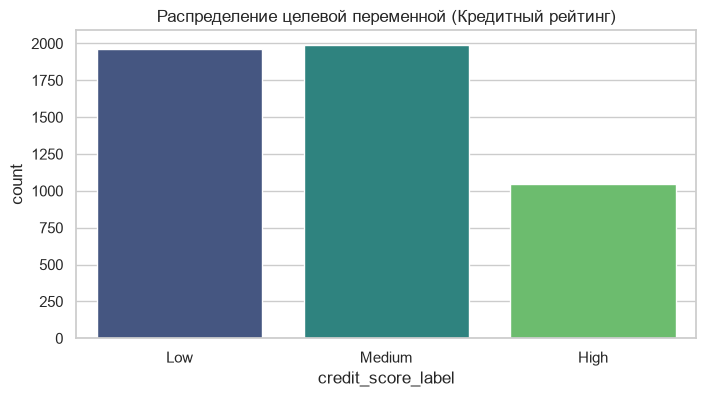


Баланс классов (доли):
credit_score_label
Medium    0.398
Low       0.393
High      0.209
Name: proportion, dtype: float64


In [31]:
# Приведение типов
expected_cat_cols = ['gender', 'education_level', 'season', 'soil_texture', 'land_cover_type', 'soc_class_label']
# Собираем только те колонки, которые реально есть в датасете
actual_cat_cols = [c for c in expected_cat_cols if c in df.columns]

# Проверяем, каких колонок не хватает
missing = set(expected_cat_cols) - set(actual_cat_cols)
if missing:
    print(f"В датасете нет колонок: {missing}")

for col in actual_cat_cols:
    df[col] = df[col].astype('category')

print(f"Преобразованы в категории: {actual_cat_cols}")

if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

print("\nОписательная статистика числовых признаков:")
display(df.describe().T)
display(df.describe(include='category').T) # Статистика по категориям

# Распределение целевой переменной
if 'credit_score_label' in df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x='credit_score_label', hue='credit_score_label', palette='viridis', legend=False)
    plt.title('Распределение целевой переменной (Кредитный рейтинг)')
    plt.show()
    
    print("\nБаланс классов (доли):")
    print(df['credit_score_label'].value_counts(normalize=True))

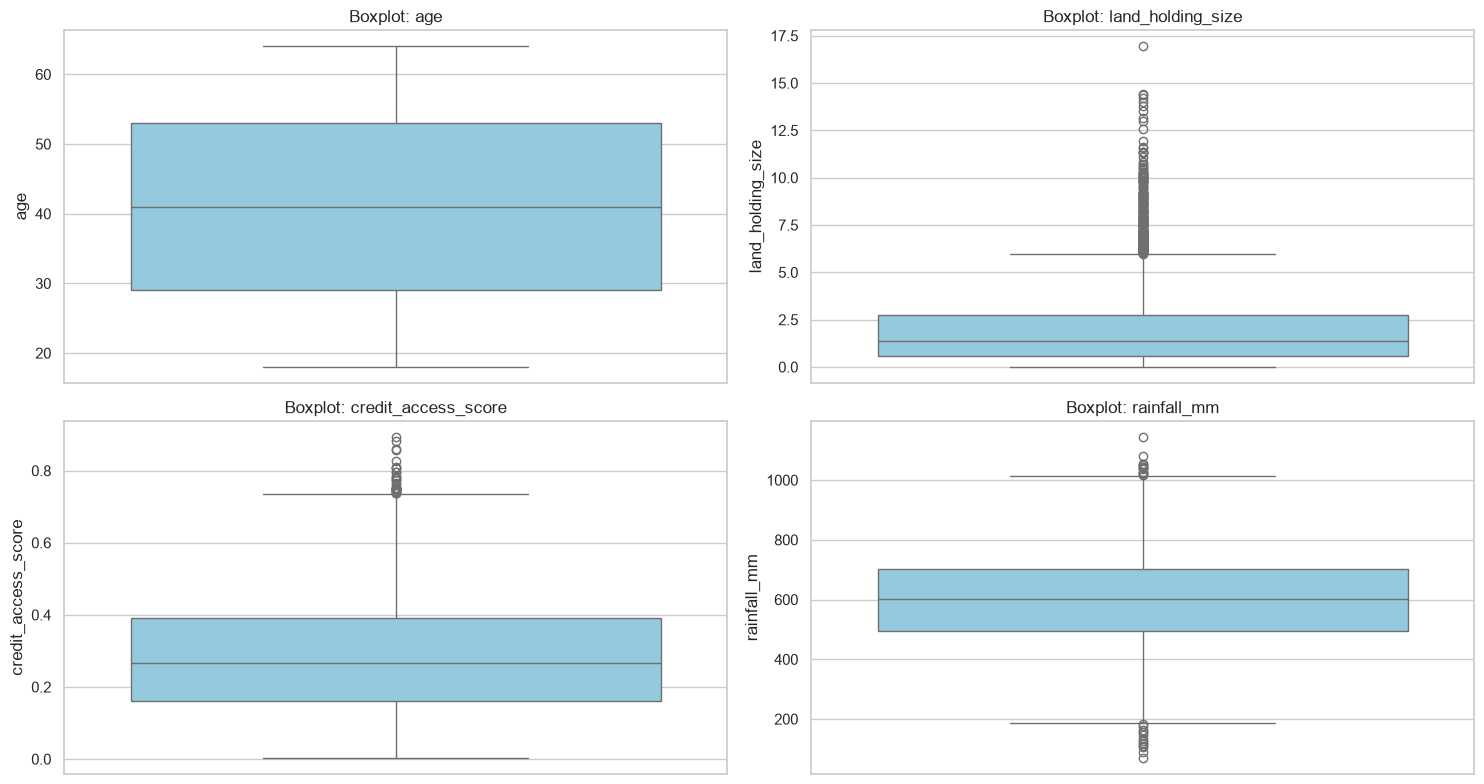

Математический поиск выбросов (метод IQR):
- age: 0 выбросов (0.00%)
- land_holding_size: 238 выбросов (4.76%)
- credit_access_score: 32 выбросов (0.64%)
- rainfall_mm: 28 выбросов (0.56%)


In [32]:
# Визуализируем распределения и найдем экстремальные значения методом IQR

num_cols = ['age', 'land_holding_size', 'credit_access_score', 'rainfall_mm']
num_cols = [col for col in num_cols if col in df.columns]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot: {col}')

plt.tight_layout()
plt.show()

print("Математический поиск выбросов (метод IQR):")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"- {col}: {len(outliers)} выбросов ({(len(outliers)/len(df))*100:.2f}%)")

In [33]:
print("--- Проверка физических границ признаков ---")

# Словарь с допустимыми физическими границами
bounds = {
    'soc_percent': (0, np.inf),  # Углерод в почве не может быть отрицательным
    'soil_ph': (0, 14),          # Шкала pH от 0 до 14
    'ndvi': (-1, 1),             # Индекс NDVI от -1 до 1
    'evi': (-1, 1)               # Индекс EVI от -1 до 1
}

for col, (min_val, max_val) in bounds.items():
    if col in df.columns:
        # Ищем строки, где значения выходят за рамки
        invalid_rows = df[(df[col] < min_val) | (df[col] > max_val)]
        
        if not invalid_rows.empty:
            print(f"Внимание! Признак '{col}' имеет {len(invalid_rows)} логических аномалий.")
            print(f"Недопустимые значения: {invalid_rows[col].unique()[:5]} (допустимо: от {min_val} до {max_val})")
        else:
            print(f"Признак '{col}': в пределах физических норм.")

--- Проверка физических границ признаков ---
Внимание! Признак 'soc_percent' имеет 19 логических аномалий.
Недопустимые значения: [-0.05 -0.2  -0.02 -0.01 -0.08] (допустимо: от 0 до inf)
Признак 'soil_ph': в пределах физических норм.
Признак 'ndvi': в пределах физических норм.
Признак 'evi': в пределах физических норм.


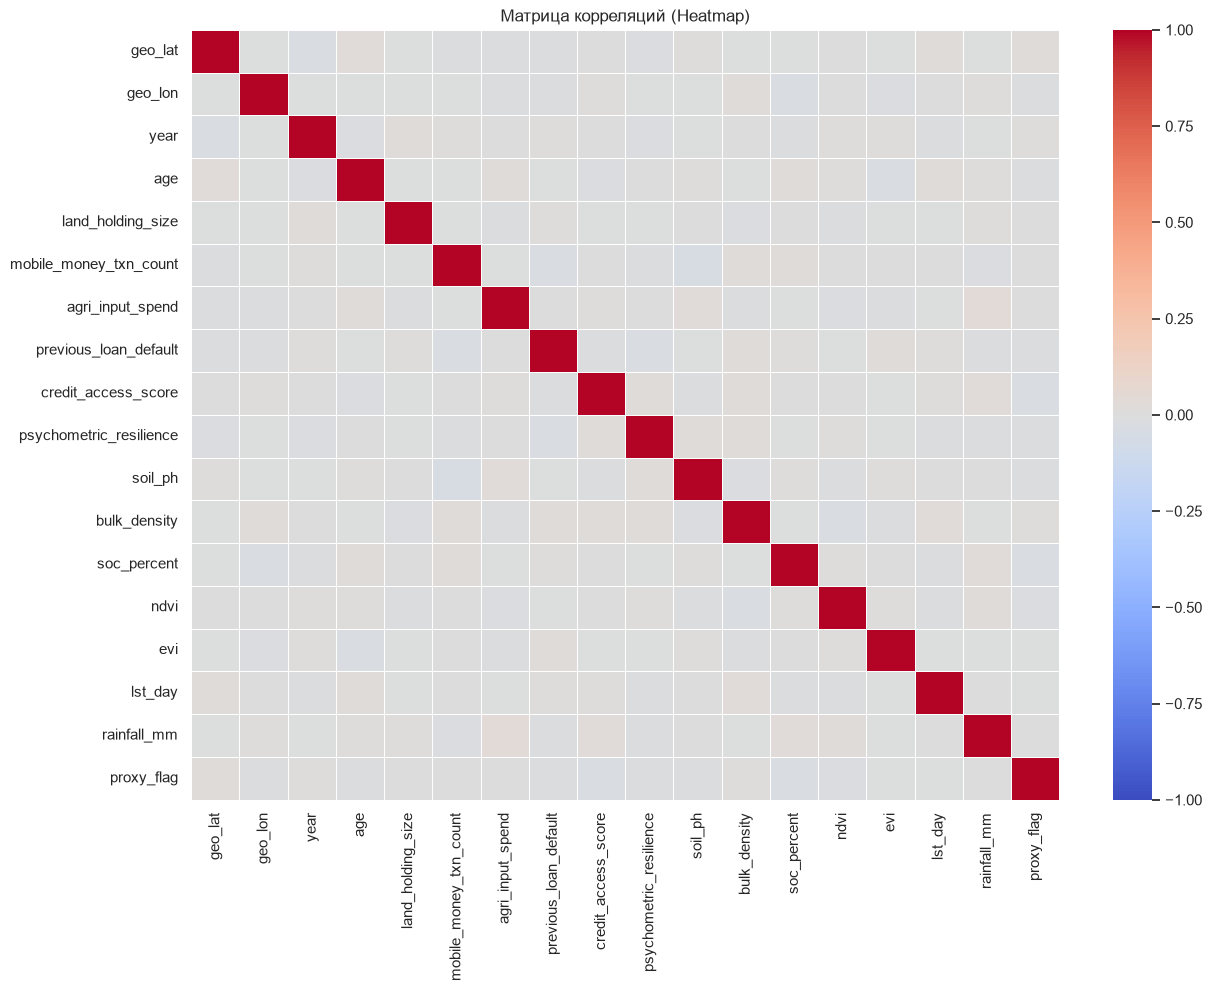


5 корреляций по модулю (среди слабых/средних/сильных):


,Признак 1,Признак 2,Корреляция
100,mobile_money_txn_count,soil_ph,-0.042955
124,agri_input_spend,rainfall_mm,0.037063
160,credit_access_score,rainfall_mm,0.030923
161,credit_access_score,proxy_flag,-0.026791
2,geo_lat,year,-0.026674


In [34]:
# Оценка корреляции между числовыми признаками
numeric_df = df.select_dtypes(include=[np.number]) 

plt.figure(figsize=(14, 10))
corr_matrix = numeric_df.corr()

# Построение тепловой карты
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Матрица корреляций (Heatmap)')
plt.show()

# Получаем уникальные пары корреляций
# np.triu оставляет только верхний треугольник матрицы
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_pairs = upper_tri.stack().reset_index()
corr_pairs.columns = ['Признак 1', 'Признак 2', 'Корреляция']

# Сортируем по модулю корреляции
corr_pairs['abs_corr'] = corr_pairs['Корреляция'].abs()
top_corr = corr_pairs.sort_values(by='abs_corr', ascending=False).drop('abs_corr', axis=1)

# Вывод результата
print("\n5 корреляций по модулю (среди слабых/средних/сильных):")
display(top_corr.head(5))

# Data quality отчёт:

### 1. Ключевые метрики
*   **Полнота:** Общая заполненность датасета составляет ~99%. 
*   **Уникальность:** Первичный ключ `household_id` уникален. Полных дубликатов строк не обнаружено.
*   **Аномалии:** Признак `land_holding_size` имеет тяжелый правый хвост (выбросы до 16.93 при медиане 1.39 — логнормальное распределение). В `soc_percent` есть физически невозможные отрицательные значения (до -0.33). Признак `age` чистый.

### 2. ETL-план
На основе выявленных проблем в пайплайн подготовки данных необходимо встроить следующие шаги:
1.  **Заполнение пропусков:** В признаке `education_level` пропущено 30.86% данных. Проверка показала, что пропуски, скорее всего, случайны (нет жесткой привязки к другим признакам), поэтому заполнение модой или категорией 'Unknown' исказит данные минимально.
2.  **Обработка выбросов:** Для `land_holding_size` применить логарифмирование (`np.log1p`) или клиппинг, чтобы стабилизировать дисперсию перед линейными моделями.
3.  **Обработка логических аномалий:** Выявлен признак `soc_percent` с отрицательными значениями (физически невозможно). В ETL-пайплайне необходимо заменить такие значения на 0 (или `NaN` с последующим заполнением пропусков).
4.  **Кодирование:** Применить One-Hot Encoding к категориальным признакам.

**Вывод:** Датасет пригоден для дальнейшего анализа и построения моделей после выполнения описанных шагов по очистке.